In [10]:
import pandas as pd
import numpy as np

model_results = {
    "LightGBM": {
        "ROC AUC": 0.889,
        "Accuracy": 0.736,
        "Confusion Matrix": np.array([[5065, 1939], [51, 476]]),
        
        "Precision (Class 0)": 0.99, 
        "Recall (Class 0)": 0.72,    
        "F1-Score (Class 0)": 0.83,
        
        "Precision (Class 1)": 0.20, 
        "Recall (Class 1)": 0.90,    
        "F1-Score (Class 1)": 0.32, 
    },

    "Random Forest": {
        "ROC AUC": 0.871,
        "Accuracy": 0.912,
        "Confusion Matrix": np.array([[6752, 230], [435, 114]]),
        
        "Precision (Class 0)": 0.94,
        "Recall (Class 0)": 0.96,
        "F1-Score (Class 0)": 0.95,

        "Precision (Class 1)": 0.33, 
        "Recall (Class 1)": 0.21,    
        "F1-Score (Class 1)": 0.26, 
    },

    "XGBoost": {
        "ROC AUC": 0.849,
        "Accuracy": 0.922,
        "Confusion Matrix": np.array([[6901, 81], [506, 43]]),
        
        "Precision (Class 0)": 0.93,
        "Recall (Class 0)": 0.98,
        "F1-Score (Class 0)": 0.95,

        "Precision (Class 1)": 0.35, 
        "Recall (Class 1)": 0.08,    
        "F1-Score (Class 1)": 0.13, 
    },

    "Logistic Regression": {
        "ROC AUC": 0.816,
        "Accuracy": 0.763,
        "Confusion Matrix": np.array([[5359, 1623], [162, 387]]),
        
        "Precision (Class 0)": 0.97,
        "Recall (Class 0)": 0.76,
        "F1-Score (Class 0)": 0.85,

        "Precision (Class 1)": 0.19, 
        "Recall (Class 1)": 0.70,    
        "F1-Score (Class 1)": 0.30, 
    },

    "Decision Tree": {
        "ROC AUC": 0.813,
        "Accuracy": 0.835,
        "Confusion Matrix": np.array([[6042, 940], [301, 248]]),
        
        "Precision (Class 0)": 0.95,
        "Recall (Class 0)": 0.86,
        "F1-Score (Class 0)": 0.90,

        "Precision (Class 1)": 0.21, 
        "Recall (Class 1)": 0.45,    
        "F1-Score (Class 1)": 0.29, 
    }
}

In [11]:
def create_comparison_df(results):
    comparison_data = {
        model: {
            'ROC AUC': data['ROC AUC'],
            'Accuracy': data['Accuracy'],
            
            # Low Fatality (Class 0) Metrics
            'P (Class 0)': data['Precision (Class 0)'],
            'R (Class 0)': data['Recall (Class 0)'],
            'F1 (Class 0)': data['F1-Score (Class 0)'],
            
            # High Fatality (Class 1) Metrics (CRITICAL)
            'P (Class 1)': data['Precision (Class 1)'],
            'R (Class 1)': data['Recall (Class 1)'],
            'F1 (Class 1)': data['F1-Score (Class 1)'],
            
        } for model, data in results.items()
    }
    df = pd.DataFrame.from_dict(comparison_data, orient='index')
    return df

In [12]:
def print_detailed_report(model_name, data):
    print(f"\nDetailed Results: {model_name}")
    
    print("\nOverall Summary:")
    print(f"- Accuracy: {data['Accuracy']:}")
    print(f"- ROC AUC: {data['ROC AUC']:}")

    print("\nLow Fatality (Class 0) Metrics:")
    print(f"- Precision: {data['Precision (Class 0)']:}")
    print(f"- Recall: {data['Recall (Class 0)']:}")
    print(f"- F1-Score: {data['F1-Score (Class 0)']:}")

    print("\nHigh Fatality (Class 1) Metrics (CRITICAL):")
    print(f"- Precision: {data['Precision (Class 1)']:}")
    print(f"- Recall: {data['Recall (Class 1)']:}")
    print(f"- F1-Score: {data['F1-Score (Class 1)']:}")

    print("\nConfusion Matrix:")
    cm_df = pd.DataFrame(
        data["Confusion Matrix"], 
        index=['Actual Low', 'Actual High'], 
        columns=['Predicted Low', 'Predicted High']
    )
    print(cm_df)
    


if __name__ == '__main__':
    comparison_table = create_comparison_df(model_results)
    
    print("==============================================================================================================================================================")
    print("                                                 Model Performance Comparison Table                                                                           ")
    print("==============================================================================================================================================================")
    print(comparison_table.to_string()) 
    print("\n\n")
    print("=============================================================================================")
    print("                       Model Selection Justification (LightGBM)                              """)
    print("=============================================================================================")
    print("""
The LightGBM model is the best choice for this safety-critical task.

1.  Superior Recall (90.0%): The primary goal is to minimize False Negatives 
    (missed fatal crashes). LGBM successfully identifies 90% of all high-fatality 
    events, which is significantly better than Random Forest (21.0%) and XGBoost (8.0%).
          
2.  Highest ROC AUC (0.889): This indicates the best overall discriminatory power.

3. F1-Score Stability: LightGBM's F1-Score of 0.320 is the highest among all models, 
   demonstrating that while it favors Recall, it is not completely neglecting Precision.
""")
    print_detailed_report("LightGBM (Selected)", model_results["LightGBM"])


                                                 Model Performance Comparison Table                                                                           
                     ROC AUC  Accuracy  P (Class 0)  R (Class 0)  F1 (Class 0)  P (Class 1)  R (Class 1)  F1 (Class 1)
LightGBM               0.889     0.736         0.99         0.72          0.83         0.20         0.90          0.32
Random Forest          0.871     0.912         0.94         0.96          0.95         0.33         0.21          0.26
XGBoost                0.849     0.922         0.93         0.98          0.95         0.35         0.08          0.13
Logistic Regression    0.816     0.763         0.97         0.76          0.85         0.19         0.70          0.30
Decision Tree          0.813     0.835         0.95         0.86          0.90         0.21         0.45          0.29



                       Model Selection Justification (LightGBM)                              

The LightGBM model is the bes

C:\Users\Hp\AppData\Local\Temp\ipykernel_19416\231138887.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inte

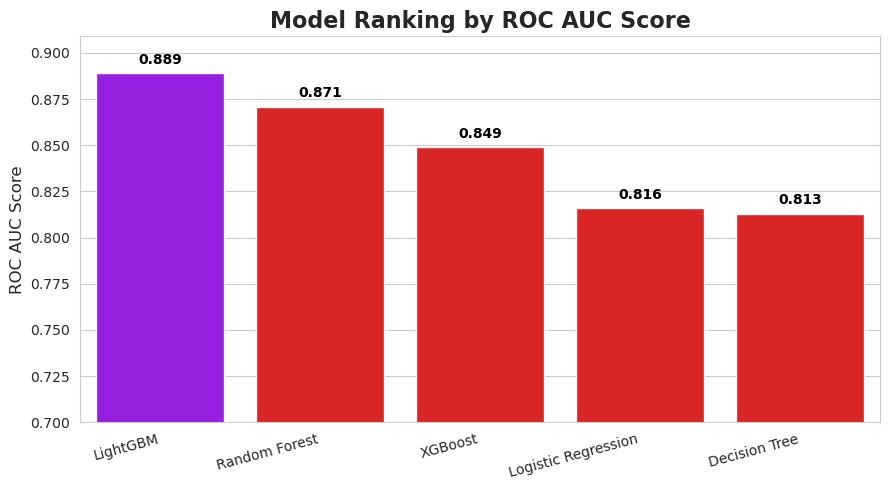

findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because none of the following families were found: Inter
findfont: Generic family 'sans-serif' not found because

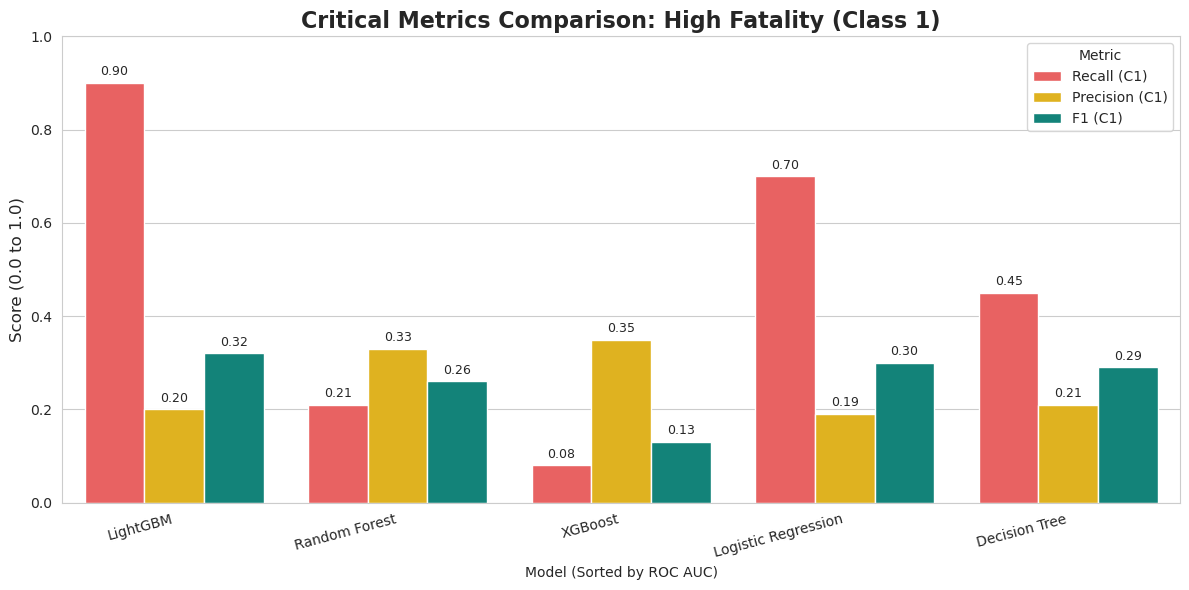

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['font.sans-serif'] = ['Inter']
plt.rcParams['figure.dpi'] = 100

model_results = {
    "LightGBM": {
        "ROC AUC": 0.889, "Accuracy": 0.736, "Confusion Matrix": np.array([[5065, 1939], [51, 476]]),
        "Precision (Class 0)": 0.99, "Recall (Class 0)": 0.72, "F1-Score (Class 0)": 0.83,
        "Precision (Class 1)": 0.20, "Recall (Class 1)": 0.90, "F1-Score (Class 1)": 0.32, 
    },
    "Random Forest": {
        "ROC AUC": 0.871, "Accuracy": 0.912, "Confusion Matrix": np.array([[6752, 230], [435, 114]]),
        "Precision (Class 0)": 0.94, "Recall (Class 0)": 0.96, "F1-Score (Class 0)": 0.95,
        "Precision (Class 1)": 0.33, "Recall (Class 1)": 0.21, "F1-Score (Class 1)": 0.26, 
    },
    "XGBoost": {
        "ROC AUC": 0.849, "Accuracy": 0.922, "Confusion Matrix": np.array([[6901, 81], [506, 43]]),
        "Precision (Class 0)": 0.93, "Recall (Class 0)": 0.98, "F1-Score (Class 0)": 0.95,
        "Precision (Class 1)": 0.35, "Recall (Class 1)": 0.08, "F1-Score (Class 1)": 0.13, 
    },
    "Logistic Regression": {
        "ROC AUC": 0.816, "Accuracy": 0.763, "Confusion Matrix": np.array([[5359, 1623], [162, 387]]),
        "Precision (Class 0)": 0.97, "Recall (Class 0)": 0.76, "F1-Score (Class 0)": 0.85,
        "Precision (Class 1)": 0.19, "Recall (Class 1)": 0.70, "F1-Score (Class 1)": 0.30, 
    },
    "Decision Tree": {
        "ROC AUC": 0.813, "Accuracy": 0.835, "Confusion Matrix": np.array([[6042, 940], [301, 248]]),
        "Precision (Class 0)": 0.95, "Recall (Class 0)": 0.86, "F1-Score (Class 0)": 0.90,
        "Precision (Class 1)": 0.21, "Recall (Class 1)": 0.45, "F1-Score (Class 1)": 0.29, 
    }
}

def prepare_data_for_plotting(results):
    """Extracts and structures key metrics into a DataFrame for visualization."""
    model_data_list = []
    for model_name, data in results.items():
        model_data_list.append({
            "Model": model_name,
            "ROC AUC": data["ROC AUC"],
            "Recall (C1)": data["Recall (Class 1)"],
            "Precision (C1)": data["Precision (Class 1)"],
            "F1 (C1)": data["F1-Score (Class 1)"],
        })
    df = pd.DataFrame(model_data_list)
    return df.sort_values(by='ROC AUC', ascending=False).reset_index(drop=True)

df_metrics = prepare_data_for_plotting(model_results)

def plot_roc_auc_comparison(df):
    """Generates a bar plot comparing models by ROC AUC score."""
    plt.figure(figsize=(9, 5))
    colors = ["#9D00FF" if model == 'LightGBM' else "#F70707" for model in df['Model']]
    
    ax = sns.barplot(
        x='Model',
        y='ROC AUC',
        data=df,
        palette=colors
    )
    plt.title('Model Ranking by ROC AUC Score', fontsize=16, weight='bold')
    plt.ylabel('ROC AUC Score', fontsize=12)
    plt.xlabel('')
    plt.ylim(0.7, df['ROC AUC'].max() + 0.02)
    plt.xticks(rotation=15, ha='right')
    for p in ax.patches:
        ax.text(p.get_x() + p.get_width() / 2., p.get_height() + 0.005, 
                f"{p.get_height():.3f}", 
                color='black', ha="center", fontsize=10, weight='semibold')
        
    plt.tight_layout()
    plt.show()

def plot_critical_metrics(df):
    """Generates a grouped bar plot comparing Recall, Precision, and F1 for the critical Class 1."""
    df_melted = df.melt(
        id_vars='Model', 
        value_vars=['Recall (C1)', 'Precision (C1)', 'F1 (C1)'],
        var_name='Metric', 
        value_name='Score'
    )
    
    plt.figure(figsize=(12, 6))
    ax = sns.barplot(
        x='Model',
        y='Score',
        hue='Metric',
        data=df_melted,
        palette=['#FF4B4B', '#FFC300', '#009688'] 
    )
    
    plt.title('Critical Metrics Comparison: High Fatality (Class 1)', fontsize=16, weight='bold')
    plt.ylabel('Score (0.0 to 1.0)', fontsize=12)
    plt.xlabel('Model (Sorted by ROC AUC)')
    plt.ylim(0.0, 1.0)
    plt.legend(title='Metric', loc='upper right')
    plt.xticks(rotation=15, ha='right')
    
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.text(p.get_x() + p.get_width() / 2., height + 0.01,
                    f'{height:.2f}', ha='center', va='bottom', fontsize=9)
            
    plt.tight_layout()
    plt.show()

if __name__ == '__main__':
    plot_roc_auc_comparison(df_metrics)
    plot_critical_metrics(df_metrics)
